# Partie 4 — Analyse croisée météo × pollution × vélos
Jointures sur `(city, hour)` (heure UTC arrondie) des trois fichiers `*_city_hourly.parquet`, puis 4 questions.

**Prudence** : les données vélos couvrent environ 20 h → on parle de **tendances observées**. Corrélation ≠ causalité ; l'heure de la journée est un facteur de confusion (trafic, usage des vélos et pollution ont tous un rythme quotidien).

In [1]:
import sys, warnings, importlib.util
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

# Charte graphique de Redouane (figures/style.py) : on tente d'appeler sa fonction d'initialisation
try:
    spec = importlib.util.spec_from_file_location("style", ROOT / "figures" / "style.py")
    style = importlib.util.module_from_spec(spec); spec.loader.exec_module(style)
    for _fn in ("apply", "set_style", "use", "setup", "init", "apply_style"):
        if hasattr(style, _fn):
            getattr(style, _fn)(); break
except Exception as e:
    print("style.py non chargé :", e); sns.set_theme(style="whitegrid")

PREFIX = "p4"
def save(fig, name):
    fig.savefig(FIG / f"{PREFIX}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 0. Chargement, jointures
⚠️ Adapter les noms de fichiers/colonnes (dictionnaires `COLW`, `COLP`, `COLB`) aux fichiers réels après `git pull`.

In [2]:
CLEAN = ROOT / "data" / "clean"
print("Fichiers city_hourly disponibles :", sorted(p.name for p in CLEAN.glob("*city_hourly.parquet")))

PATH_W = CLEAN / "weather_city_hourly.parquet"
PATH_P = CLEAN / "pollution_city_hourly.parquet"
PATH_B = CLEAN / "bikes_city_hourly.parquet"
PATH_W_RECENT = CLEAN / "weather_recent_city_hourly.parquet"     # plan B Open-Meteo (fourni par le chef)
REQUIRED_PATHS = [PATH_W, PATH_P, PATH_B]
missing = [path for path in REQUIRED_PATHS if not path.is_file()]
if missing:
    available = sorted(p.name for p in CLEAN.glob("*city_hourly.parquet"))
    missing_list = "\n".join(f"  - {path}" for path in missing)
    raise FileNotFoundError(
        "Parquet requis pour le croisement introuvables :\n"
        f"{missing_list}\n"
        f"Fichiers city_hourly présents dans {CLEAN} : {available or 'aucun'}\n"
        "Générez ou copiez ces Parquet dans data/clean avant d'exécuter le notebook."
    )

COLW = dict(temp="temp_c", wind="wind_ms", precip="precip_mm", period="precip_period_h")
COLP = dict(no2="no2", pm25="pm25", pm10="pm10", o3="o3")
COLB = dict(mov="movements")
KEYS = ["city", "hour"]

def load(path):
    d = pd.read_parquet(path)
    d["hour"] = pd.to_datetime(d["hour"], utc=True).dt.floor("h")
    try:
        from urbanhub_utils import check_city_hourly; check_city_hourly(d)
    except Exception as e:
        print(path.name, "check_city_hourly :", e)
    return d

def add_rain(d):
    """Pluie horaire : on ne garde que les cumuls sur 1 h quand la colonne de période existe."""
    pr = d[COLW["precip"]]
    if COLW["period"] in d.columns: pr = pr.where(d[COLW["period"]] == 1)
    return d.assign(precip_1h=pr)

w_noaa, p, b = add_rain(load(PATH_W)), load(PATH_P), load(PATH_B)
# Retard de publication NOAA : si la météo NOAA ne recouvre pas la pollution (ici NOAA s'arrête en août 2025,
# pollution et vélos portent sur oct.-nov. 2026), on utilise la météo Open-Meteo (plan B) pour toute la partie 4.
USE_WEATHER_PLAN_B = len(w_noaa.merge(p, on=KEYS, how="inner")) == 0
w = add_rain(load(PATH_W_RECENT)) if USE_WEATHER_PLAN_B else w_noaa
print("Météo utilisée :", "Open-Meteo (plan B)" if USE_WEATHER_PLAN_B else "NOAA")
wp = w.merge(p, on=KEYS, how="inner")
wpb = wp.merge(b, on=KEYS, how="inner")
for name, d in [("météo", w), ("pollution", p), ("vélos", b), ("wp = météo × pollution", wp), ("wpb = wp × vélos", wpb)]:
    if len(d): print(f"{name:25s} {len(d):>8d} lignes | {d['hour'].min()} -> {d['hour'].max()} | villes : {d['city'].nunique()}")
    else: print(f"{name:25s} VIDE")

Fichiers city_hourly disponibles : ['bikes_city_hourly.parquet', 'pollution_city_hourly.parquet', 'weather_city_hourly.parquet', 'weather_recent_city_hourly.parquet']


check_city_hourly OK : 320890 lignes, 8 villes, 2021-01-01 00:00:00+00:00 -> 2025-08-24 21:00:00+00:00
check_city_hourly OK : 5474 lignes, 8 villes, 2026-10-22 15:00:00+00:00 -> 2026-11-21 13:00:00+00:00
check_city_hourly OK : 141 lignes, 7 villes, 2026-11-19 16:00:00+00:00 -> 2026-11-20 13:00:00+00:00
check_city_hourly OK : 1464 lignes, 8 villes, 2026-11-14 00:00:00+00:00 -> 2026-11-21 14:00:00+00:00
Météo utilisée : Open-Meteo (plan B)
météo                         1464 lignes | 2026-11-14 00:00:00+00:00 -> 2026-11-21 14:00:00+00:00 | villes : 8
pollution                     5474 lignes | 2026-10-22 15:00:00+00:00 -> 2026-11-21 13:00:00+00:00 | villes : 8
vélos                          141 lignes | 2026-11-19 16:00:00+00:00 -> 2026-11-20 13:00:00+00:00 | villes : 7
wp = météo × pollution        1336 lignes | 2026-11-14 00:00:00+00:00 -> 2026-11-21 13:00:00+00:00 | villes : 8
wpb = wp × vélos               117 lignes | 2026-11-19 18:00:00+00:00 -> 2026-11-20 13:00:00+00:00 | villes : 

In [3]:
# Plan B : si la jointure avec les vélos est vide (la météo NOAA a quelques jours de retard),
# on utilise la météo Open-Meteo récente pour Q2/Q3 (météo × vélos) uniquement.
USE_PLAN_B = USE_WEATHER_PLAN_B or len(wpb) == 0
if len(wpb) == 0:
    print("⚠️ wpb vide -> PLAN B : météo Open-Meteo (weather_recent_city_hourly) pour Q2/Q3")
    wb = add_rain(load(PATH_W_RECENT)).merge(b, on=KEYS, how="inner")
    print("wb (Open-Meteo × vélos) :", len(wb), "lignes |", wb["hour"].min(), "->", wb["hour"].max())
else:
    wb = wpb.copy()

T, WD, MOV = COLW["temp"], COLW["wind"], COLB["mov"]
wb["hod"] = wb["hour"].dt.tz_convert("Europe/Paris").dt.hour                    # heure de la journée (Paris)
# Sur ~20 h de collecte il n'y a qu'une observation par (ville, heure) : un indice « par heure » vaudrait 1 partout.
# On compare donc à la moyenne de la même ville DANS LA MÊME TRANCHE DE JOURNÉE (nuit, matin, après-midi, soir).
wb["daypart"] = pd.cut(wb["hod"], [0, 6, 12, 18, 24], right=False, labels=["nuit 0-6 h", "matin 6-12 h", "après-midi 12-18 h", "soir 18-24 h"])
wb["mov_idx"] = wb[MOV] / wb.groupby(["city", "daypart"], observed=True)[MOV].transform("mean")   # mouvements relatifs à la tranche de journée
wb["rain"] = np.where(wb["precip_1h"] > 0, "Pluie", "Pas de pluie")
TB_BINS, TB_LAB = [-50, 5, 10, 15, 20, 25, 60], ["<5", "5–10", "10–15", "15–20", "20–25", ">25"]
wb["temp_bin"] = pd.cut(wb[T], TB_BINS, labels=TB_LAB)
print("Plan B utilisé :", USE_PLAN_B)

Plan B utilisé : True


> **Note méthodologique** : l'indice de mouvements = mouvements de la mesure / moyenne des mouvements de la même ville dans la même **tranche de journée** (nuit, matin, après-midi, soir). Un indice 1 = usage habituel à ce moment de la journée. Comme la collecte vélos ne couvre qu'environ 20 h (19–20/11/2026), on ne peut pas neutraliser le rythme quotidien heure par heure : l'indice par tranche en est une approximation.

## Q1 — Vent ↔ NO2/PM, température ↔ O3, pluie ↔ PM
**Méthode** : corrélations de Spearman sur les couples (city, hour) de `wp`.

CHIFFRE CLÉ — corrélations de Spearman :
          couple    n    rho  p_value
      Vent ↔ NO2 1274 -0.560      0.0
    Vent ↔ PM2.5 1312 -0.415      0.0
     Vent ↔ PM10 1250 -0.328      0.0
Température ↔ O3 1242  0.284      0.0
   Pluie ↔ PM2.5 1312 -0.216      0.0
    Pluie ↔ PM10 1250 -0.308      0.0


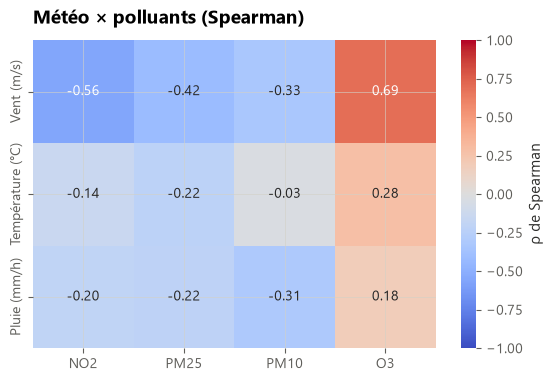

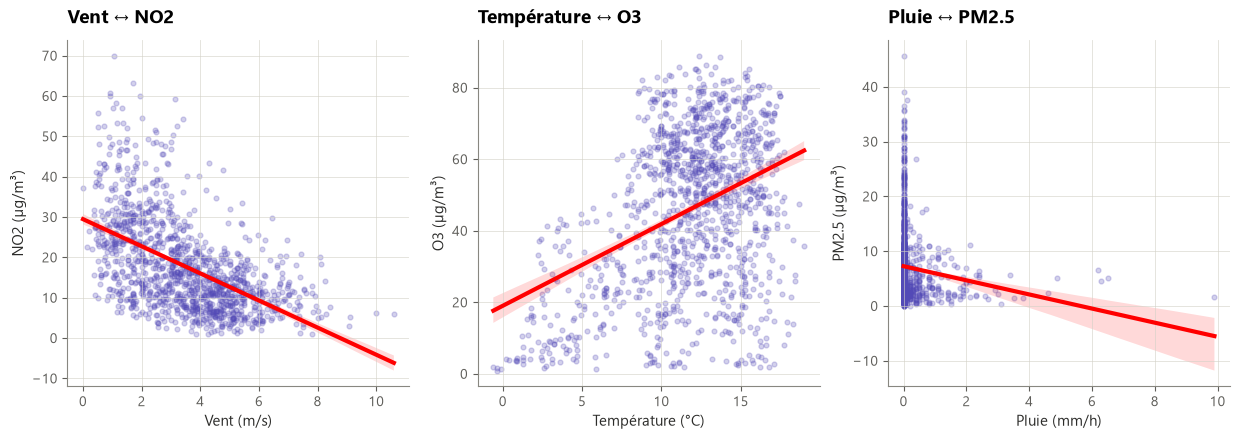

In [4]:
assert len(wp) > 0, "wp vide : vérifier les bornes temporelles de météo et pollution"
pairs = [(WD, COLP["no2"], "Vent ↔ NO2"), (WD, COLP["pm25"], "Vent ↔ PM2.5"), (WD, COLP["pm10"], "Vent ↔ PM10"),
         (T, COLP["o3"], "Température ↔ O3"), ("precip_1h", COLP["pm25"], "Pluie ↔ PM2.5"), ("precip_1h", COLP["pm10"], "Pluie ↔ PM10")]
rows = []
for x, y, lab in pairs:
    d = wp[[x, y]].dropna()
    if len(d) > 10:
        r = stats.spearmanr(d[x], d[y]); rows.append((lab, len(d), r.statistic, r.pvalue))
q1 = pd.DataFrame(rows, columns=["couple", "n", "rho", "p_value"]).round(3)
print("CHIFFRE CLÉ — corrélations de Spearman :"); print(q1.to_string(index=False))

wcols = {WD: "Vent (m/s)", T: "Température (°C)", "precip_1h": "Pluie (mm/h)"}
pcols = {v: k.upper() for k, v in COLP.items()}
cm = wp[list(wcols) + list(pcols)].rename(columns={**wcols, **pcols}).corr(method="spearman").loc[list(wcols.values()), list(pcols.values())]
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "ρ de Spearman"})
ax.set_title("Météo × polluants (Spearman)"); save(fig, "q1_heatmap")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (x, y, lab, xl, yl) in zip(axes, [(WD, COLP["no2"], "Vent ↔ NO2", "Vent (m/s)", "NO2 (µg/m³)"),
                                          (T, COLP["o3"], "Température ↔ O3", "Température (°C)", "O3 (µg/m³)"),
                                          ("precip_1h", COLP["pm25"], "Pluie ↔ PM2.5", "Pluie (mm/h)", "PM2.5 (µg/m³)")]):
    d = wp[[x, y]].dropna(); d = d.sample(min(len(d), 3000), random_state=0)
    sns.regplot(data=d, x=x, y=y, scatter_kws={"alpha": 0.25, "s": 12}, line_kws={"color": "red"}, ax=ax)
    ax.set(title=lab, xlabel=xl, ylabel=yl)
save(fig, "q1_regplots")

**Q1 — Méthode → chiffre clé → interprétation**
- Méthode : Spearman météo × polluants sur `wp`, heatmap + `regplot`.
- Chiffre clé : ρ vent ↔ NO2 = −0,56 (n = 1 274) ; vent ↔ PM2.5 = −0,42 (n = 1 312) ; vent ↔ PM10 = −0,33 (n = 1 250) ; température ↔ O3 = +0,28 (n = 1 242) ; pluie ↔ PM2.5 = −0,22 (n = 1 312) ; pluie ↔ PM10 = −0,31 (n = 1 250). Tous significatifs (p < 0,001). La heatmap montre aussi vent ↔ O3 = +0,69, la corrélation la plus forte du graphique.
- Interprétation : Plus le vent est fort, plus NO2 et particules sont faibles : le vent disperse les polluants primaires, l'effet le plus net (NO2). L'ozone est plus élevé quand il fait plus chaud (formation photochimique), l'association restant modérée. Le vent est aussi associé à plus d'ozone (ρ = +0,69), ce qui peut refléter un air mieux mélangé et moins d'ozone détruit par le NO2 local : hypothèse à vérifier. La pluie va avec des particules plus faibles, compatible avec un lessivage. Corrélation ≠ causalité : température, vent et pluie varient aussi avec le cycle quotidien.

## Q2 — Mouvements de vélos : pluie et température
**Méthode** : indice de mouvements (à heure comparable) selon pluie / pas de pluie et par tranche de température.

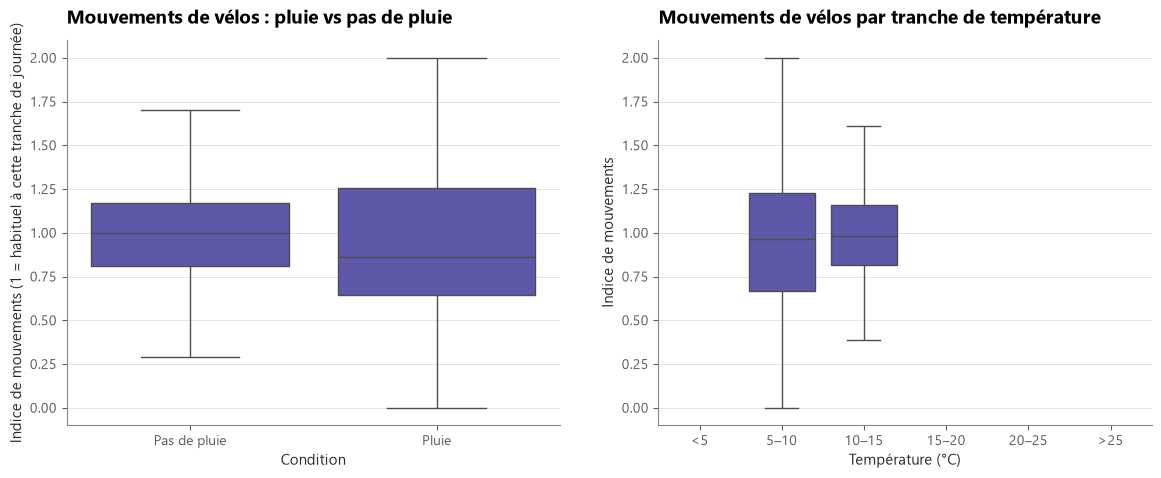

CHIFFRE CLÉ — indice médian : {'Pas de pluie': 1.0, 'Pluie': 0.86} | n pluie = 36 | n sec = 81
Mann-Whitney p-value : 0.2171
          median  size
temp_bin              
5–10        0.96    33
10–15       0.98    84


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=wb, x="rain", y="mov_idx", showfliers=False, ax=axes[0])
axes[0].set(title="Mouvements de vélos : pluie vs pas de pluie", xlabel="Condition", ylabel="Indice de mouvements (1 = habituel à cette tranche de journée)")
sns.boxplot(data=wb, x="temp_bin", y="mov_idx", showfliers=False, ax=axes[1])
axes[1].set(title="Mouvements de vélos par tranche de température", xlabel="Température (°C)", ylabel="Indice de mouvements")
save(fig, "q2_boxplots")

med = wb.groupby("rain")["mov_idx"].median()
a_, b_ = (wb.loc[wb["rain"] == k, "mov_idx"].dropna() for k in ("Pluie", "Pas de pluie"))
print("CHIFFRE CLÉ — indice médian :", med.round(2).to_dict(), "| n pluie =", len(a_), "| n sec =", len(b_))
if len(a_) > 5 and len(b_) > 5: print("Mann-Whitney p-value :", round(stats.mannwhitneyu(a_, b_).pvalue, 4))
print(wb.groupby("temp_bin")["mov_idx"].agg(["median", "size"]).round(2))

**Q2 — Méthode → chiffre clé → interprétation**
- Méthode : indice de mouvements relatif à la même ville et à la même tranche de journée ; boxplots pluie / pas de pluie et par tranche de température.
- Chiffre clé : indice médian 0,86 sous la pluie (n = 36) contre 1,00 sans pluie (n = 81) ; test de Mann-Whitney p = 0,22 (non significatif). Par température : 0,96 entre 5 et 10 °C (n = 33) et 0,98 entre 10 et 15 °C (n = 84), seules tranches observées.
- Interprétation : Les mouvements semblent environ 14 % plus faibles sous la pluie, mais la différence n'est pas statistiquement significative sur cet échantillon. La température n'a pas d'effet net sur une plage aussi étroite (5 à 15 °C). Tendance observée sur ~20 h seulement.

## Q3 — Meilleure combinaison pluie × vent < 5 m/s × température
**Méthode** : indice moyen de mouvements par combinaison (pluie, classe de vent) × tranche de température ; cellules avec moins de `MIN_N` observations masquées.

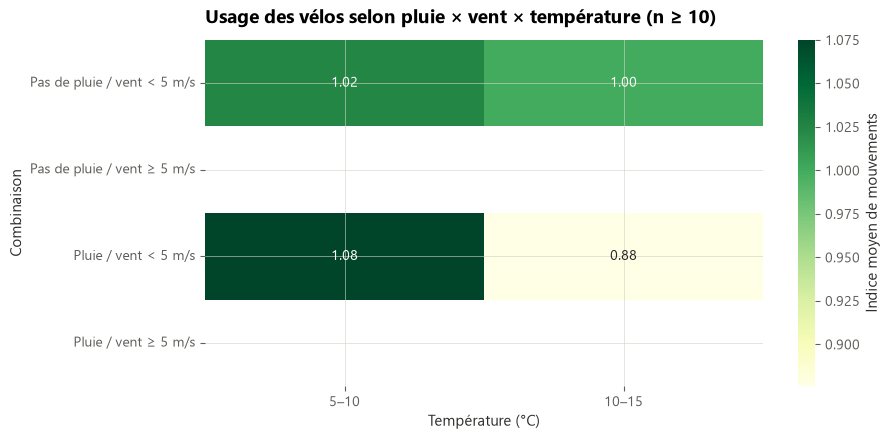

CHIFFRE CLÉ — meilleure combinaison : ('Pluie / vent < 5 m/s', '5–10') | indice = 1.08 | n = 14

Top 5 :
combo                        temp_bin
Pluie / vent < 5 m/s         5–10        1.08
Pas de pluie / vent < 5 m/s  5–10        1.02
                             10–15       1.00
Pluie / vent < 5 m/s         10–15       0.88
Pas de pluie / vent ≥ 5 m/s  5–10         NaN
dtype: float64


In [6]:
MIN_N = 10
wb["wind_class"] = np.where(wb[WD] < 5, "vent < 5 m/s", "vent ≥ 5 m/s")
wb["combo"] = wb["rain"] + " / " + wb["wind_class"]
piv = wb.pivot_table(index="combo", columns="temp_bin", values="mov_idx", aggfunc="mean")
cnt = wb.pivot_table(index="combo", columns="temp_bin", values="mov_idx", aggfunc="size")
piv_m = piv.where(cnt >= MIN_N)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.heatmap(piv_m, annot=True, fmt=".2f", cmap="YlGn", ax=ax, cbar_kws={"label": "Indice moyen de mouvements"})
ax.set(title=f"Usage des vélos selon pluie × vent × température (n ≥ {MIN_N})", xlabel="Température (°C)", ylabel="Combinaison")
save(fig, "q3_heatmap_combinaisons")

best = piv_m.stack().sort_values(ascending=False)
print("CHIFFRE CLÉ — meilleure combinaison :", best.index[0], "| indice =", round(best.iloc[0], 2), "| n =", int(cnt.loc[best.index[0]]))
print("\nTop 5 :"); print(best.head(5).round(2))

**Q3 — Méthode → chiffre clé → interprétation**
- Méthode : heatmap de l'indice moyen par combinaison pluie × vent × température, cellules de moins de 10 observations masquées.
- Chiffre clé : meilleure combinaison observée : pluie, vent < 5 m/s, 5–10 °C, indice 1,08 (n = 14) ; sans pluie, vent < 5 m/s : 1,02 (5–10 °C) et 1,00 (10–15 °C). Aucune cellule « vent ≥ 5 m/s » n'atteint 10 observations.
- Interprétation : Les écarts entre combinaisons sont faibles (indice entre 0,88 et 1,08) et ne permettent pas de désigner de condition clairement favorable ; le résultat « pluie » en tête est un artefact d'échantillon (n = 14), pas un effet réel. L'effet du vent fort ne peut pas être testé. Il faudrait une collecte de plusieurs semaines.

## Q4 — Vue d'ensemble : Paris et corrélation globale
**Méthode** : z-scores superposés (mouvements, NO2, PM2.5, température) pour Paris + heatmap de corrélation de toutes les variables.

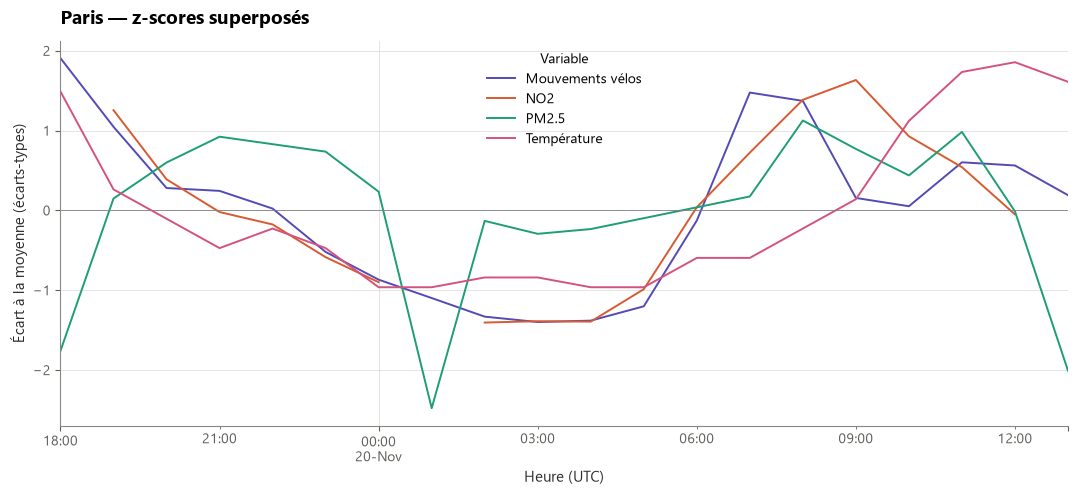

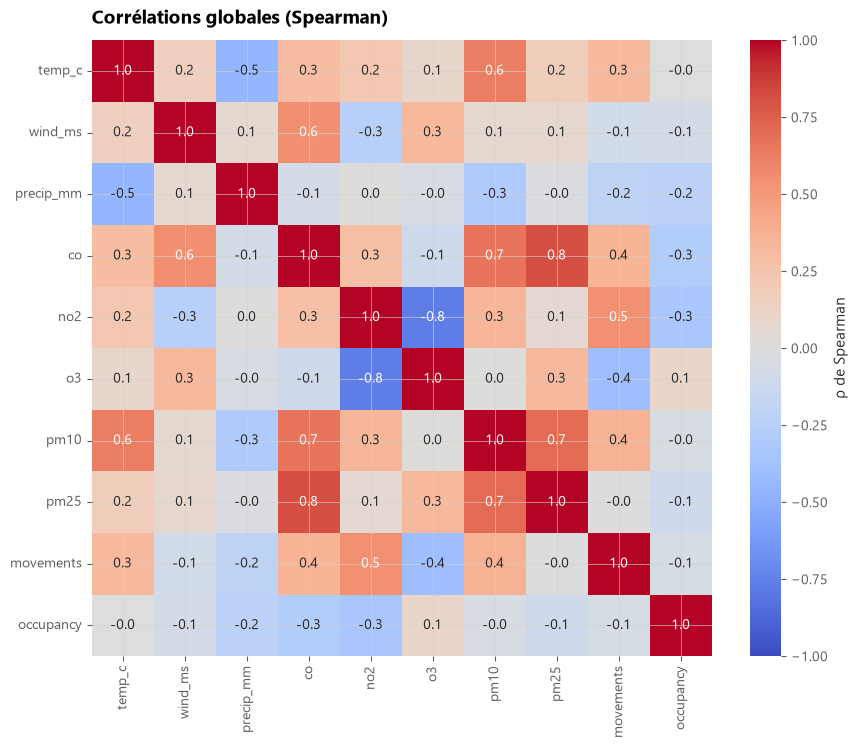

CHIFFRE CLÉ — corrélations avec les mouvements de vélos :
o3          -0.40
precip_mm   -0.21
wind_ms     -0.08
occupancy   -0.05
pm25        -0.01
temp_c       0.32
co           0.35
pm10         0.37
no2          0.55
Name: movements, dtype: float64


In [7]:
base = wpb if len(wpb) else wb          # sans wpb (plan B), on reste sur les variables disponibles dans wb
series = {MOV: "Mouvements vélos", COLP["no2"]: "NO2", COLP["pm25"]: "PM2.5", T: "Température"}
series = {k: v for k, v in series.items() if k in base.columns}
par = base[base["city"] == "Paris"].sort_values("hour").set_index("hour")[list(series)].rename(columns=series)
z = (par - par.mean()) / par.std()

fig, ax = plt.subplots(figsize=(13, 5))
z.plot(ax=ax, lw=1.4)
ax.set(title="Paris — z-scores superposés", xlabel="Heure (UTC)", ylabel="Écart à la moyenne (écarts-types)")
ax.axhline(0, color="grey", lw=0.6); ax.legend(title="Variable"); save(fig, "q4_zscores_paris")

num = base.select_dtypes("number").drop(columns=["mov_idx", "hod", "precip_1h"], errors="ignore")
num = num.loc[:, num.nunique() > 1]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, cbar_kws={"label": "ρ de Spearman"})
ax.set_title("Corrélations globales (Spearman)"); save(fig, "q4_heatmap_globale")
print("CHIFFRE CLÉ — corrélations avec les mouvements de vélos :")
print(num.corr(method="spearman")[MOV].drop(MOV).sort_values().round(2) if MOV in num else "n/a")

**Q4 — Méthode → chiffre clé → interprétation**
- Méthode : z-scores superposés (mouvements, NO2, PM2.5, température) pour Paris + heatmap de corrélation globale.
- Chiffre clé : corrélations de Spearman avec les mouvements de vélos : NO2 +0,55, PM10 +0,37, CO +0,35, température +0,32, O3 −0,40, pluie −0,21, vent −0,08, PM2.5 −0,01. Fenêtre commune : 19/11 18 h → 20/11 13 h UTC (117 lignes, 7 villes).
- Interprétation : Les vélos co-varient surtout avec le NO2 (+0,55) : tous deux suivent le trafic urbain, donc le rythme quotidien (facteur de confusion) plutôt qu'un lien causal entre l'usage du vélo et la pollution. La corrélation négative avec l'ozone reflète l'inverse du cycle jour/nuit. Tendances observées uniquement, sur une seule journée de collecte.

In [8]:
figs = sorted(p.name for p in FIG.glob("p4_*.png")); print(len(figs), "figures :", figs)

6 figures : ['p4_q1_heatmap.png', 'p4_q1_regplots.png', 'p4_q2_boxplots.png', 'p4_q3_heatmap_combinaisons.png', 'p4_q4_heatmap_globale.png', 'p4_q4_zscores_paris.png']
